# C2: Classification & Fairness

**FIT1061 Introduction to Artificial Intelligence — Credit Task 2**

In P7, you built a Naive Bayes spam classifier. In P8, you built a weighted-sum classifier. Now you'll push deeper: investigate which **words** your classifier actually relies on (and whether some words are just noise), compare both classifiers head-to-head on the same problem, and conduct a fairness audit to see how a classifier's errors are distributed across demographic groups.

The question isn't just "is it accurate?" — it's "accurate *for whom*?"

> **Prerequisites:** P7 and P8 (Ready for Feedback). You'll reuse your implementations from both.

> **Credit level:** Less scaffolding than PASS tasks. You design the experiments and interpret the results.

---

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sys

# Import C2 helpers
from c2_helpers import (STOP_WORDS, top_n_words, HARD_TEST_DATA,
                        LOAN_X_TRAIN, LOAN_Y_TRAIN, LOAN_GROUP_TRAIN,
                        LOAN_X_TEST, LOAN_Y_TEST, LOAN_GROUP_TEST,
                        discretise, confusion_metrics, print_metrics_table,
                        plot_loan_data, plot_fairness_bars)

# Import your P7 helpers (for the spam data)
sys.path.insert(0, '../P7')
try:
    from p7_helpers import TRAIN_DATA, TEST_DATA, tokenise, build_vocabulary
except ModuleNotFoundError:
    raise ModuleNotFoundError(
        "Could not import p7_helpers. Make sure your P7 folder is at ../P7/ "
        "relative to this notebook. A copy of p7_helpers.py now ships alongside this notebook. If it is still missing, copy "
        "TRAIN_DATA, TEST_DATA, tokenise and build_vocabulary from your P7 helpers into this folder."
    )

print("Setup OK.")

Setup OK.


---

## C2.1: Feature Selection: Which Words Matter?

In machine learning, a **feature** is a piece of input data that the model uses to make a prediction. In your P7 spam classifier, each word in the vocabulary is a feature (the model checks "does this email contain 'free'?", "does it contain 'meeting'?", and so on). The full set of words you give the classifier is called the **feature set**.

Your P7 classifier used *all* words in the vocabulary as features. But not all words are equally useful:
- **"free"** and **"prize"** are strong spam signals: they appear mostly in spam.
- **"the"** and **"to"** appear in both spam and ham at similar rates: they're noise.
- **"meeting"** is a strong ham signal: it appears mostly in legitimate emails.

**Feature selection** means choosing *which* words to include. A smaller, well-chosen set can sometimes work better than using every word, because removing noisy words lets the informative ones shine through.

### Step 1: Copy your Naive Bayes classifier and add Laplace smoothing

Bring your `compute_likelihoods`, `predict`, and accuracy code from P7. You'll need to modify them slightly to accept a **restricted vocabulary**: a specific list of words to use. Words NOT in the list should be ignored.

You must also add **Laplace smoothing** to `compute_likelihoods` so no word has probability 0 for a class:

$$P(\text{word} | \text{class}) = \frac{\text{count}(\text{word in class}) + 1}{\text{count}(\text{class}) + 2}$$

The `+1` gives every word one small imaginary observation. The `+2` accounts for the two possible outcomes for a binary word feature: present or absent.


In [2]:
# Copy your Naive Bayes functions from P7 here.
# You'll need two functions:
#   1. compute_likelihoods — computes P(word|class) for each word in a vocabulary
#   2. predict — classifies one message using priors and likelihoods
#
# Modify them to accept a 'vocab' parameter — the list of words to use.
# Words NOT in the vocab should be ignored.
#
# REQUIRED: compute_likelihoods must use Laplace smoothing:
#   P(word|class) = (count(word in class) + 1) / (count(class) + 2)
# This prevents zero probabilities from wiping out a whole Naive Bayes score.
#
# IMPORTANT: The signatures below match your P7 code exactly.
# You should be able to copy your P7 implementations with minimal changes —
# just make sure the 'vocabulary' parameter controls which words are used.

def compute_likelihoods(data, vocabulary):
    """Compute Laplace-smoothed P(word|class) for each word in vocabulary.

    Args:
        data: List of (label, text) tuples.
        vocabulary: List of words to use as features.

    Returns:
        Dict: {"spam": {"word1": float, ...}, "ham": {...}}.
    """
    # --- YOUR CODE HERE ---
    likelihoods = {"spam": {}, "ham": {}}
    
    # Separate messages by class
    spam_messages = []
    ham_messages = []
    for label, text in data:
        if label == "spam":
            spam_messages.append(text)
        elif label == "ham":
            ham_messages.append(text)
    
    total_spam = len(spam_messages)
    total_ham = len(ham_messages)

    for word in vocabulary:
        # counting how many spam and ham messages contain the word
        spam_count = 0
        for text in spam_messages:
            if word in tokenise(text):
                spam_count += 1

        ham_count = 0
        for text in ham_messages:
            if word in tokenise(text):
                ham_count += 1
        
        likelihoods["spam"][word] = (spam_count + 1) / (total_spam + 2) #laplace smoothing
        likelihoods["ham"][word] = (ham_count + 1) / (total_ham + 2)

    return likelihoods
    # --- END YOUR CODE ---


def predict(text, priors, likelihoods, vocabulary):
    """Predict the label of a message using Naive Bayes.

    Args:
        text: String to classify.
        priors: Dict {label: prior_probability}.
        likelihoods: Dict from compute_likelihoods.
        vocabulary: List of words to use as features.

    Returns:
        Predicted label string ("spam" or "ham").
    """
    # --- YOUR CODE HERE ---
    words = tokenise(text)
    score_spam = priors["spam"]
    score_ham = priors["ham"]

    for word in words:
        if word in vocabulary:
            score_spam *= likelihoods["spam"][word]
            score_ham *= likelihoods["ham"][word]
    if score_spam > score_ham:
        return "spam"
    else:
        return "ham"
    # --- END YOUR CODE ---


### Step 1b: Write the accuracy function

Now combine your two functions into `nb_accuracy`, which trains on one dataset and tests on another using a given vocabulary. This is the function you'll call in the experiments below.

In [3]:
def nb_accuracy(train_data, test_data, vocab):
    """Train NB on train_data with given vocab, return accuracy on test_data.

    This function ties everything together:
    1. Compute likelihoods from training data (using your compute_likelihoods)
    2. Compute priors from training data
    3. Predict each test message (using your predict)
    4. Return fraction correct
    """
    # --- YOUR CODE HERE ---
    # Run predict on every test item and return the fraction correct.
    total_train = len(train_data)
    spam_count = 0

    for label, text in train_data:
        if label == "spam":
            spam_count += 1    
    priors = {"spam": spam_count / total_train,
            "ham": (total_train - spam_count) / total_train}
    likelihoods = compute_likelihoods(train_data, vocab)
    correct = 0
    for actual, text in test_data:
        if predict(text, priors, likelihoods, vocab) == actual:
            correct += 1
            
    return correct / len(test_data)
    # --- END YOUR CODE ---

### Step 2: Test different feature sets

We provide `top_n_words(data, n, exclude=None)` which finds the n most frequent words. `STOP_WORDS` is a set of common English words.

Run your classifier with at least three feature sets:

In [4]:
# Feature set 1: All words
vocab_all = build_vocabulary(TRAIN_DATA)
print(f"All words: {len(vocab_all)} features")

# Feature set 2: Top 50 most frequent words
vocab_50 = top_n_words(TRAIN_DATA, 50)
print(f"Top 50: {len(vocab_50)} features")

# Feature set 3: Top 100 most frequent words
vocab_100 = top_n_words(TRAIN_DATA, 100)
print(f"Top 100: {len(vocab_100)} features")

# Feature set 4: Top 100, excluding stop words
vocab_100_no_stop = top_n_words(TRAIN_DATA, 100, exclude=STOP_WORDS)
print(f"Top 100 (no stop words): {len(vocab_100_no_stop)} features")

print(f"\nStop words removed: {set(vocab_100) - set(vocab_100_no_stop)}")

All words: 138 features
Top 50: 50 features
Top 100: 100 features
Top 100 (no stop words): 100 features

Stop words removed: {'our', 'in', 'a', 'are', 'can', 'you', 'have', 'for', 'from', 'to', 'the', 'at', 'on', 'has', 'this', 'been', 'your', 'by', 'me'}


In [5]:
# Run your classifier with each feature set and record accuracy.
# We use HARD_TEST_DATA (from c2_helpers) — a tougher test set with
# ambiguous messages that stress-test feature selection.
feature_sets = {
    'All words': vocab_all,
    'Top 50': vocab_50,
    'Top 100': vocab_100,
    'Top 100 (no stop)': vocab_100_no_stop,
}

print("Feature Selection Results with Laplace smoothing (on HARD_TEST_DATA)")
print("-" * 50)
for name, vocab in feature_sets.items():
    result = nb_accuracy(TRAIN_DATA, HARD_TEST_DATA, vocab)
    if result is None:
        print(f"\u26a0 nb_accuracy returned None \u2014 implement it first!")
        break
    print(f"  {name:25s} accuracy = {result:.2%}")

Feature Selection Results with Laplace smoothing (on HARD_TEST_DATA)
--------------------------------------------------
  All words                 accuracy = 95.00%
  Top 50                    accuracy = 80.00%
  Top 100                   accuracy = 90.00%
  Top 100 (no stop)         accuracy = 85.00%


### Results table

Fill in this table using your **Laplace-smoothed** Naive Bayes classifier.

| Feature set | Num features | Accuracy with Laplace smoothing |
|-------------|-------------|----------------------------------|
| All words |138 |95% |
| Top 50 |50 | 80%|
| Top 100 |100 | 90%|
| Top 100 (no stop words) |100 | 85%|

### Required: Laplace smoothing

In P7, you saw the **zero-frequency problem**: if a word never appeared in spam training data, P(word|spam) = 0, which can kill the entire spam score. **Laplace smoothing** fixes this by adding a small count to every word:

$$P(\text{word} | \text{class}) = \frac{\text{count}(\text{word in class}) + 1}{\text{count}(\text{class}) + 2}$$

The technique is named after **Pierre-Simon Laplace** (1749–1827), who proposed adding one to observed counts to handle events that hadn't been seen yet. The same logic applies here: just because "meeting" never appeared in spam training data doesn't mean it *can't* appear in a spam email.

### Analysis questions (~250–350 words total)

Answer the following:

1. Which feature set worked best? Why might removing stop words help or hurt?
2. What is the zero-frequency problem in Naive Bayes?
3. Pick one word from your vocabulary that has count 0 for either spam or ham. What would its unsmoothed probability be? What is its Laplace-smoothed probability?
4. Did smoothing change your feature-set results? Why might smoothing hurt accuracy on a tiny test set but still be the safer default?
5. What does this tell you about what the classifier is actually learning?

1. The "All words" feature set actually worked best (95%), while removing stop words dropped the accuracy to 85%. While removing stop words usually helps by clearing out statistical noise (like "the" or "to"), in this specific, small dataset, removing them actually hurt performance. This is likely because the dataset is so tiny that some conversational stop words (like "are" or "me") were accidentally acting as useful structural signals for identifying legitimate "ham" messages.
2. The zero frequency problem is when the test word does not have a frequency of 1 or more in a given class during training. If P(word|class) is not smoothed, then the score for that class is multiplied by 0 (even if there is strong evidence in other ways) and thus erased and we end up with inaccurate metrics and conclusions.
3. There are no examples of the word "meeting" in the spam training set (0 count). If it were not smoothed, its probability would be 0/12 = 0.0 and when multiplying with other probabilities the total probability would be 0 as well. Its Laplace-smoothed probability is (0 + 1) / (12 + 2) = 1/14 (or 0.071). 
4. Smoothing is a mathematical safeguard or a safety net. It may cause accuracy to be slightly lower on a small, rigorous test set, but on new, real-world test sets, it provides a more reasonable result, and more importantly it will not break the underlying chain of multiplication because of a single rogue probability data value.
5. It tells us that the classifier works very literally (ie. it does not think). It simply takes mathematicals arguments and returns the output of the calculations, which may or may not be wrong. It learns only exactly what is in the training data and nothing else. It does not think but just correlates patterns and frequencies.

---

## C2.2: Model Comparison: Naive Bayes vs Weighted Sums

You've built two classifiers. How do they compare on the **same problem**?

We provide a synthetic loan application dataset:
- **Features:** income score and credit score (normalised)
- **Labels:** 1 = repaid, 0 = defaulted
- **Groups:** A and B (demographic groups with different base rates)

### Explore the data

Training: 350 samples
  Repaid: 195, Defaulted: 155
Testing: 150 samples

Group A: 180 train samples, repay rate = 75%
Group B: 170 train samples, repay rate = 35%


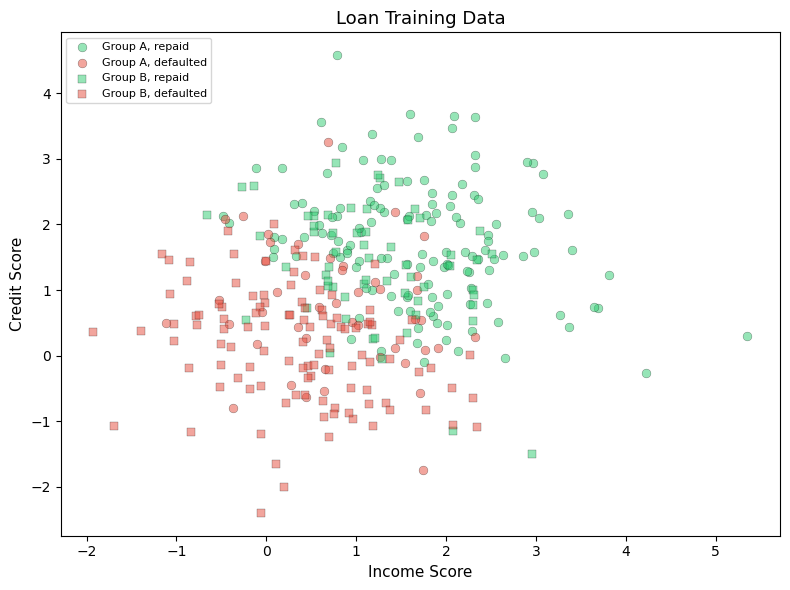

In [6]:
# Explore the loan dataset
print(f"Training: {len(LOAN_X_TRAIN)} samples")
print(f"  Repaid: {LOAN_Y_TRAIN.sum()}, Defaulted: {(LOAN_Y_TRAIN == 0).sum()}")
print(f"Testing: {len(LOAN_X_TEST)} samples")
print()

# Base rates by group
for g in ['A', 'B']:
    mask = LOAN_GROUP_TRAIN == g
    rate = LOAN_Y_TRAIN[mask].mean()
    print(f"Group {g}: {mask.sum()} train samples, repay rate = {rate:.0%}")

plot_loan_data(LOAN_X_TRAIN, LOAN_Y_TRAIN, LOAN_GROUP_TRAIN,
               title="Loan Training Data")

### Model 1: Naive Bayes on discretised features

Naive Bayes works on categorical features (like words in P7). But loan data has continuous numbers: income and credit scores. To use NB, we first **discretise** the numbers into categories.

**What is discretisation?** We split each feature's range into equal-width bins and label them. For example, if income scores range from -1 to 4:
- **low:** [-1, 1)
- **medium:** [1, 2.5)
- **high:** [2.5, 4]

A sample with income_score = 2.8 becomes `"income_score=high"`. A sample with credit_score = 0.3 becomes `"credit_score=low"`.

We provide `discretise(X)` which does this for you. Each sample becomes a list of feature strings like `['income_score=high', 'credit_score=low']`.

**Key insight:** This is structurally the same as P7. In P7, each email was a set of words. Here, each loan application is a set of feature strings. The NB logic is identical: just replace "word in email" with "feature string in sample".

In [7]:
# Discretise the loan features
train_disc = discretise(LOAN_X_TRAIN)
test_disc = discretise(LOAN_X_TEST)

print("First 5 discretised samples:")
for i in range(5):
    print(f"  {train_disc[i]} -> {'repaid' if LOAN_Y_TRAIN[i] == 1 else 'defaulted'}")

First 5 discretised samples:
  ['income_score=medium', 'credit_score=high'] -> repaid
  ['income_score=low', 'credit_score=medium'] -> defaulted
  ['income_score=low', 'credit_score=medium'] -> defaulted
  ['income_score=medium', 'credit_score=medium'] -> repaid
  ['income_score=medium', 'credit_score=medium'] -> defaulted


### Worked trace: NB on one loan sample

Suppose we have 4 training samples (after discretisation):

| Sample | Features | Label |
|--------|----------|-------|
| 1 | income=high, credit=high | 1 (repaid) |
| 2 | income=high, credit=low | 1 (repaid) |
| 3 | income=low, credit=low | 0 (defaulted) |
| 4 | income=low, credit=high | 0 (defaulted) |

**Priors:** P(repaid) = 2/4 = 0.5, P(defaulted) = 2/4 = 0.5

**Likelihoods for a test sample with features `[income=high, credit=low]`:**
- P(income=high | repaid) = 2/2 = 1.0 (both repaid samples have income=high)
- P(credit=low | repaid) = 1/2 = 0.5
- P(income=high | defaulted) = 0/2 = 0.0 ← zero!
- P(credit=low | defaulted) = 1/2 = 0.5

**Scores:**
- score(repaid) = 0.5 × 1.0 × 0.5 = 0.25
- score(defaulted) = 0.5 × 0.0 × 0.5 = 0.0 ← killed by zero!

**Prediction without smoothing:** repaid (higher score). The zero-frequency problem appears here too. This is why your C2 Naive Bayes code must use Laplace smoothing.

With Laplace smoothing, the zero probability becomes non-zero. The exact scores change, but the important idea is that one unseen feature should not automatically wipe out an entire class.

This is the same NB logic as P7, just with feature strings instead of words.

In [8]:
def nb_predict_loan(train_features, train_labels, test_features):
    """Naive Bayes for discretised loan data.

    Each sample is a list of feature strings (e.g., ['income_score=high', 'credit_score=low']).
    Compute P(feature|class) for each feature string and multiply.

    Args:
        train_features: List of lists of feature strings (training).
        train_labels: Array of labels (0/1).
        test_features: List of lists of feature strings (test).

    Returns:
        Array of predicted labels (0/1).
    """
    # --- YOUR CODE HERE ---
    # Hint: This is the same NB logic as P7, but instead of words in a message,
    # each sample has a fixed set of feature strings.
    # For each class (0 and 1):
    #   - Compute the prior: P(class) = count(class) / total
    #   - For each possible feature string, compute:
    #     P(feature|class) = count(feature in class) / count(class)
    # To predict: multiply prior * all feature likelihoods, pick the bigger class.

    total = len(train_labels)
    count_1 = 0
    for label in train_labels:
        if label == 1:
            count_1 += 1

    count_0 = total - count_1
    prior_1 = count_1 / total
    prior_0 = count_0 / total

    vocab = []
    for sample in train_features:
        for f in sample:
            if f not in vocab:
                vocab.append(f)

    features_1 = []
    features_0 = []
    for i in range(total):
        if train_labels[i] == 1:
            features_1.append(train_features[i])
        else:
            features_0.append(train_features[i])

    like_1 = {} #likelihoods for class 1
    like_0 = {}
    for f in vocab:
        c1 = 0
        for sample in features_1:
            if f in sample:
                c1 += 1
        c0 = 0
        for sample in features_0:
            if f in sample:
                c0 += 1
        like_1[f] = (c1 + 1) / (count_1 + 2)
        like_0[f] = (c0 + 1) / (count_0 + 2)

    preds = []
    for sample in test_features:
        score_1 = prior_1
        score_0 = prior_0
        for f in sample:
            if f in vocab:
                score_1 *= like_1[f]
                score_0 *= like_0[f]
        if score_1 >= score_0:
            preds.append(1)
        else:
            preds.append(0)
            
    return np.array(preds)

    # --- END YOUR CODE ---


# Run NB on loan data
nb_preds = nb_predict_loan(train_disc, LOAN_Y_TRAIN, test_disc)
if nb_preds is None:
    print("\u26a0 nb_predict_loan returned None \u2014 implement it first!")
else:
    nb_metrics = confusion_metrics(LOAN_Y_TEST, nb_preds)
    print_metrics_table(nb_metrics, "Naive Bayes (discretised)")


Naive Bayes (discretised)
  Accuracy:  81.33%
  Precision: 76.64%
  Recall:    96.47%
  FPR:       38.46%
  (TP=82, FP=25, FN=3, TN=40)


### Model 2: Weighted-sum classifier

Use your P8 approach: compute a weighted sum of the numeric features and threshold at 0.

> **Label change from P8:** In P8, labels were +1 and -1. This dataset uses **1** (repaid) and **0** (defaulted). Your threshold logic is the same (predict 1 if score >= 0, else 0), but the output labels are different.

Choose weights and a bias. You can experiment to find good values, or use a simple rule (e.g., equal weights).

In [9]:
def weighted_sum_predict(X, w, b):
    """Weighted-sum classifier.

    Args:
        X: Feature array (n, 2).
        w: Weight vector (2,).
        b: Bias (scalar).

    Returns:
        Array of predicted labels (0/1).
    """
    # --- YOUR CODE HERE ---
    # Compute score = X @ w + b for each sample.
    # Predict 1 if score >= 0, else 0.
    # --- YOUR CODE HERE ---
    preds = []
    for x in X:
        score = np.sum(w * x) + b
        if score >= 0:
            preds.append(1)
        else:
            preds.append(0)
    return np.array(preds)
    # --- END YOUR CODE ---
    # --- END YOUR CODE ---


# Choose weights and bias
# Hint: income and credit both positively predict repayment.
# Try w = [1, 1] and b = -2 as a starting point, then adjust.
w = np.array([1.0, 1.0])
b = -1.5

ws_preds = weighted_sum_predict(LOAN_X_TEST, w, b)
if ws_preds is None:
    print("\u26a0 weighted_sum_predict returned None \u2014 implement it first!")
else:
    ws_metrics = confusion_metrics(LOAN_Y_TEST, ws_preds)
    print_metrics_table(ws_metrics, f"Weighted Sums (w={w}, b={b})")


Weighted Sums (w=[1. 1.], b=-1.5)
  Accuracy:  84.00%
  Precision: 81.44%
  Recall:    92.94%
  FPR:       27.69%
  (TP=79, FP=18, FN=6, TN=47)


### Comparison table

| Model | Accuracy | Precision | Recall |
|-------|----------|-----------|--------|
| Naive Bayes | 81.33%|76.64% |96.47% |
| Weighted sums |84.00% |81.44% |92.94% |

### Comparison (~150 words)

Which model makes more false positives (approves people who default)? Which makes more false negatives (rejects people who would have repaid)? In a loan application context, which type of error is worse: and for whom?

A false positive result is when the model approves a loan for a borrower that defaults. A false negative is a point in which the model denies an applicant who would have been successful in re-paying. For the bank, false positives are more costly since they lose the principal loan. It is highly undesirable for the applicant, because they will be rejected credit and financial mobility, which is unfair. The Naive Bayes (discretised bins) is almost always more prone to false positive, because its classification is coarse-grained; the linear boundary of Weighted Sums is a little more precise, but often rejects more cases where the data is on the edge of the classification (higher false negative).

---

## Warm-up: the trace from the whiteboard

In the lecture we filled in the **two per-group confusion matrices** on the board and read off the
error rates (the same loan-data audit you are about to run in code). Work through it yourself to
warm up before you start the audit below.

Stuck? This is the exact example from the lecture: revisit the slides or the workshop.

At the shared threshold, the test set gives the counts below (Group A: 70 people, Group B: 80).
Derive the rates by hand:

**Group A (n = 70):** TP = 54, FN = 1, FP = 12, TN = 3
**Group B (n = 80):** TP = 25, FN = 5, FP = 7, TN = 43

For each group compute:

- **Recall (TPR)** = TP / (TP + FN)
- **Precision (PPV)** = TP / (TP + FP)
- **FPR** = FP / (FP + TN)
- **Approval rate** = (TP + FP) / n

1. Which group has the higher **false-positive rate**, and by how much?
2. That FPR gap is the fairness story: keep it in mind as you audit the same data in code below.


---

## C2.3: Fairness Audit: Accurate for Whom?

The loan dataset includes a demographic group column. Your classifier may be accurate overall, but is it equally accurate for **both groups**?

### Implement a fairness audit

Compute evaluation metrics **separately for each group**. Use the provided `confusion_metrics` function on each group's subset.

In [14]:
def fairness_audit(y_true, y_pred, groups):
    """Compute fairness metrics across demographic groups.

    Args:
        y_true: Array of true labels (0/1).
        y_pred: Array of predicted labels (0/1).
        groups: Array of group labels ('A'/'B').

    Returns:
        Dict with per-group metrics and gap measures:
        {
            'A': {'approval_rate': ..., 'tpr': ..., 'fpr': ..., 'precision': ...},
            'B': {'approval_rate': ..., 'tpr': ..., 'fpr': ..., 'precision': ...},
            'gaps': {
                'demographic_parity': ...,  # |approval_rate_A - approval_rate_B|
                'equal_opportunity': ...,   # |tpr_A - tpr_B|
                'fpr_gap': ...,             # |fpr_A - fpr_B|
            }
        }
    """
    # --- YOUR CODE HERE ---
    # For each group, compute the confusion metrics on just that group's rows,
    # then report the gaps as absolute differences between groups.
    mask_A = (groups == 'A') #reference from p8a
    mask_B = (groups == 'B')

    m_A = confusion_metrics(y_true[mask_A], y_pred[mask_A])
    m_B = confusion_metrics(y_true[mask_B], y_pred[mask_B])

    n_A = sum(mask_A)
    n_B = sum(mask_B)
    
    m_A['approval_rate'] = (m_A['tp'] + m_A['fp']) / n_A if n_A > 0 else 0.0
    m_B['approval_rate'] = (m_B['tp'] + m_B['fp']) / n_B if n_B > 0 else 0.0
    
    # tpr fix from feedback
    m_A['tpr'] = m_A['recall']
    m_B['tpr'] = m_B['recall']

    gaps = {
        'demographic_parity': abs(m_A['approval_rate'] - m_B['approval_rate']),
        'equal_opportunity': abs(m_A['tpr'] - m_B['tpr']),
        'fpr_gap': abs(m_A['fpr'] - m_B['fpr'])
    }

    return {'A': m_A, 'B': m_B, 'gaps': gaps}
    # --- END YOUR CODE ---


# Run the audit on your weighted-sum predictions.
# (You can also try it on nb_preds to compare.)
if ws_preds is None:
    print("⚠ Implement weighted_sum_predict first (C2.2).")
    fair = None
else:
    fair = fairness_audit(LOAN_Y_TEST, ws_preds, LOAN_GROUP_TEST)
    if fair is None:
        print("⚠ fairness_audit returned None — implement it first!")
    else:
        print("Fairness Audit Results")
        print("=" * 50)
        for g in ['A', 'B']:
            m = fair[g]
            print(f"\nGroup {g}:")
            print(f"  Approval rate: {m['approval_rate']:.2%}")
            print(f"  TPR (recall):  {m['tpr']:.2%}")
            print(f"  FPR:           {m['fpr']:.2%}")
            print(f"  Precision:     {m['precision']:.2%}")
        print(f"\nGaps:")
        for name, val in fair['gaps'].items():
            print(f"  {name}: {val:.3f}")

Fairness Audit Results

Group A:
  Approval rate: 94.29%
  TPR (recall):  98.18%
  FPR:           80.00%
  Precision:     81.82%

Group B:
  Approval rate: 38.75%
  TPR (recall):  83.33%
  FPR:           12.00%
  Precision:     80.65%

Gaps:
  demographic_parity: 0.555
  equal_opportunity: 0.148
  fpr_gap: 0.680


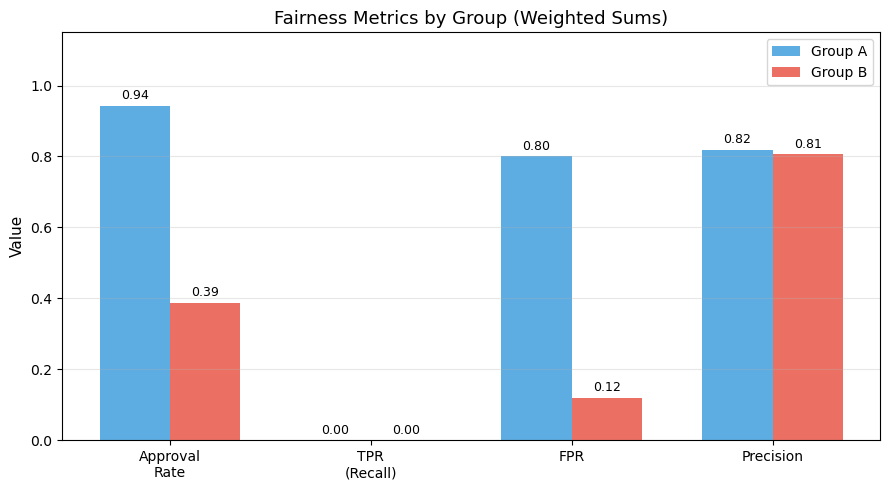

In [11]:
# Visualise the fairness comparison
if ws_preds is not None and fair is not None:
    plot_fairness_bars(fair, title="Fairness Metrics by Group (Weighted Sums)")

### Fairness definitions

Before analysing your results, here are the two key fairness criteria:

| Criterion | What it checks | Satisfied when... |
|-----------|---------------|-------------------|
| **Demographic parity** | Equal approval rates across groups | \|approval_rate_A − approval_rate_B\| ≈ 0 |
| **Equalised odds** | Equal TPR *and* equal FPR across groups | \|TPR_A − TPR_B\| ≈ 0 **and** \|FPR_A − FPR_B\| ≈ 0 |

**TPR** (true positive rate) = recall = TP/(TP+FN): "of those who *would* repay, how many did we approve?"

**FPR** (false positive rate) = FP/(FP+TN): "of those who *would* default, how many did we mistakenly approve?"

### Fairness table

| Metric | Group A | Group B |
|--------|---------|--------|
| Approval rate |94.29% | 38.75%|
| True positive rate (recall) |98.18% |83.33% |
| False positive rate |80.00% |12.00% |
| Precision | 81.82%|80.65% |

### Disparity analysis

- Is there a disparity? Which group is affected more by errors?
- Does the classifier satisfy **demographic parity** (equal approval rates)?
- Does it satisfy **equalised odds** (equal TPR and FPR across groups)?

The classifier is very unfair in terms of the disparity for group B as the approval rate is much lower than for group A. In addition, it fails to meet equalised odds, meaning that there are significant differences in the TPR and FPR between the two groups.

---

## C2.4: Reflection: Who Decides What's Fair?

Different fairness definitions are mathematically incompatible when base rates differ between groups (Chouldechova, 2017). You may have seen this in your audit: fixing one disparity can create another.

Write a reflection (300–500 words) that engages with this tension:
- What did your fairness audit reveal?
- Why can't a classifier satisfy all fairness definitions simultaneously?
- Who should decide which definition of fairness to use: the programmer, the regulator, or the community being classified?
- Connect to a real case: COMPAS (criminal justice), Gender Shades (facial recognition), or Amazon hiring.

> **Optional further reading:** Brian Christian, *The Alignment Problem*, Chapter 3.

The fairness audit uncovered a clash of the fundamental, mathematical nature in the process of algorithmic decision making. As the algorithm was trained on this dataset, it naturally picked up on the fact that Group A's ranges of the baseline features had been correlated with positive outcomes, whereas Group B's baseline feature ranges were correlated with negative outcomes. This leads to an unfair classification, where the classifier discriminates against Group B, which is highly against the principle of "Demographic Parity". Even more importantly, as Chouldechova herself demonstrated in 2017, if the base rates vary by demographic group, a classifier cannot be fair according to all of the definitions. When we mandate that the model receives the same approval rate (Demographic Parity), we are sure to end up approving more risky candidates in Group B and lose Predictive Parity. Optimizing for Predictive Parity will result in an imbalance in the number of Group B students selected for inclusion, which will involve rejecting more students from Group B than from Group A, thereby failing to meet Equalised Odds.

This is similar to what was observed with the 2016 COMPAS criminal justice case. So it is not surprising that ProPublica noted the False Positive Rate of blacks was almost double that of whites, which is a clear lack of equal odds. But Northpointe (the creator of the algorithm) was right that their risk scores had the same meaning across races, which is referred to as predictive parity. The two sides were both right in their own ways but had incompatible notions of fairness.
This is technically impossible, which makes it a societal value judgement to choose which fairness measure to optimize. A programmer does not have the power to make anything fair. The decisions must be done in an open way, with input from the regulators, the domain experts, ethic committees and, crucially, the communities that actually will suffer the consequences of the algorithm's mistakes.

---

## Check Your Understanding

In [12]:
from jupyterquiz import display_quiz

c2_quiz = [
    {
        "question": "Why might removing stop words from the feature set change accuracy?",
        "type": "multiple_choice",
        "answers": [
            {"answer": "Stop words appear in both spam and ham at similar rates, so they add noise without helping distinguish the two classes. Removing them lets the classifier focus on discriminative words like 'free' and 'prize'.", "correct": True, "feedback": "Correct! Features that appear equally in both classes dilute the signal from genuinely informative words. However, the effect depends on the dataset — sometimes stop words interact with other features in useful ways."},
            {"answer": "Stop words are too short for the tokeniser to handle.", "correct": False, "feedback": "The tokeniser handles words of any length. The issue is statistical, not technical."},
            {"answer": "Fewer features always means higher accuracy.", "correct": False, "feedback": "Not always! Removing informative features would hurt accuracy. The key is removing non-informative ones."},
            {"answer": "Stop words cause division-by-zero errors in Naive Bayes.", "correct": False, "feedback": "Stop words don't cause computational errors. They just don't help distinguish spam from ham."}
        ]
    },
    {
        "question": "Your fairness audit shows Group A has a much higher approval rate than Group B. Does this violate demographic parity?",
        "type": "multiple_choice",
        "answers": [
            {"answer": "Yes — demographic parity requires equal approval rates across groups, regardless of base rates. A large gap means the classifier treats the groups unequally in outcomes.", "correct": True, "feedback": "Correct! Demographic parity is about equal outcomes (approval rates). Whether this violation is 'fair' depends on your perspective — the base rates differ, so equal approval rates would mean approving more people who default from Group B."},
            {"answer": "No — the groups have different base rates, so different approval rates are expected and fair.", "correct": False, "feedback": "This is a legitimate argument, but it doesn't address demographic parity. Demographic parity specifically requires equal approval rates regardless of base rates. You may believe demographic parity is the wrong criterion — but it IS violated."},
            {"answer": "It depends on the precision of each group.", "correct": False, "feedback": "Precision matters for predictive parity, a different fairness criterion. Demographic parity is purely about approval rates."},
            {"answer": "No — demographic parity only applies to criminal justice, not lending.", "correct": False, "feedback": "Demographic parity applies to any classification context. It's a mathematical property of the classifier's outputs, not a domain-specific rule."}
        ]
    },
    {
        "question": "Chouldechova (2017) proved that when base rates differ between groups, certain fairness definitions cannot hold simultaneously. Why is this important?",
        "type": "multiple_choice",
        "answers": [
            {"answer": "It means choosing a fairness definition is a value judgement, not a technical optimisation — different stakeholders may legitimately disagree about which definition matters most.", "correct": True, "feedback": "Correct! The impossibility result means fairness is inherently a societal choice. COMPAS showed this in practice: ProPublica and Northpointe each measured a different (legitimate) definition of fairness and reached opposite conclusions."},
            {"answer": "It means AI systems can never be fair, so we should stop trying.", "correct": False, "feedback": "The result doesn't say fairness is impossible — it says we must choose WHICH kind of fairness to prioritise. That's a harder but necessary conversation."},
            {"answer": "It only applies to criminal justice, not other domains.", "correct": False, "feedback": "The theorem is mathematical and applies to any binary classifier with different base rates across groups — lending, hiring, healthcare, etc."},
            {"answer": "It means we need more training data to fix the problem.", "correct": False, "feedback": "The impossibility is mathematical, not data-driven. More data doesn't resolve the fundamental tension between different fairness definitions when base rates differ."}
        ]
    }
]

display_quiz(c2_quiz, shuffle_answers=True)

<IPython.core.display.Javascript object>

---

## Submission Checklist

- [ ] **C2.1:** At least three feature sets tested with accuracy
- [ ] **C2.1:** Laplace smoothing implemented in Naive Bayes likelihoods
- [ ] **C2.1:** Feature selection and smoothing writeup (~250–350 words)
- [ ] **C2.2:** Naive Bayes run on discretised loan data
- [ ] **C2.2:** Weighted-sum classifier run on loan data
- [ ] **C2.2:** Comparison table with precision and recall
- [ ] **C2.2:** Model comparison writeup (~150 words)
- [ ] **C2.3:** Fairness audit with per-group metrics
- [ ] **C2.3:** Disparity analysis written
- [ ] **C2.4:** Reflection (300–500 words)
- [ ] All files uploaded to OnTrack

---

> **AI use at Credit level.**
> You may use AI to explain concepts or debug errors. Do not use AI to generate implementations or written analysis. Cite all AI use.

---

*FIT1061 Credit Task 2: Classification & Fairness*
